In [1]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict,Literal

In [2]:
class QuadState(TypedDict):
    a:int
    b:int
    c:int
    
    equation:str
    discriminant:float
    result:str

In [3]:
def show_equation(state:QuadState):
    equation=f'{state["a"]}x2{state["b"]}x{state["c"]}'
    
    return {
        'equation':equation
    }

In [4]:
def calculate_discriminant(state:QuadState):
    
    discriminant=state["b"]**2-4*state["a"]*state["c"]
    return {'discriminant':discriminant}

In [5]:
def real_roots(state:QuadState):
    
    root1=(-state["b"]+state["discriminant"]**0.5)/(2*state["a"])
    root2=(-state["b"]-state["discriminant"]**0.5)/(2*state["a"])
    
    result=f"The roots are {root1} and {root2}."
    
    return {
        'result':result
    }
    

In [6]:
def repeated_roots(state:QuadState):
    # root=-b/2a
    root=(-state["b"])/(2*state["a"])
    
    result=f"Only repeating root is {root}."
    return {
        'result':result
    }

In [7]:
def no_real_roots(state:QuadState):
    result=f"No real roots exist."
    
    return {'result':result}

In [18]:
def check_condition(state:QuadState)->Literal["real_roots","no_real_roots","repeated_roots"]:
    
    if state["discriminant"]>0:
        return "real_roots"
    
    elif state["discriminant"]==0:
        return "repeated_roots"
    else:
        return "no_real_roots"
        

In [19]:
graph=StateGraph(QuadState)

graph.add_node('show_equation',show_equation)
graph.add_node('calculate_discriminant',calculate_discriminant)
graph.add_node('real_roots',real_roots)
graph.add_node('no_real_roots',no_real_roots)
graph.add_node('repeated_roots',repeated_roots)

# edges
graph.add_edge(START,'show_equation')
graph.add_edge('show_equation','calculate_discriminant')

graph.add_conditional_edges('calculate_discriminant',check_condition)
graph.add_edge('real_roots',END)
graph.add_edge('repeated_roots',END)
graph.add_edge('no_real_roots',END)

workflow=graph.compile()

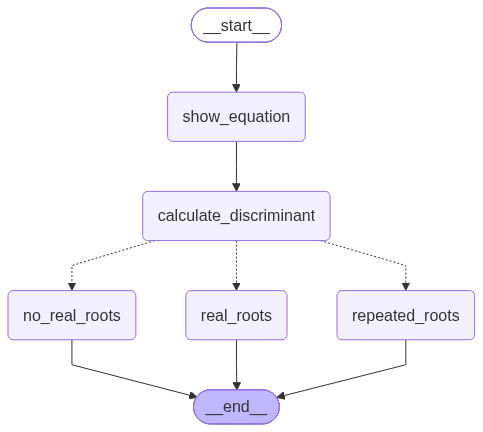

In [20]:
workflow

In [21]:
initial_state={
    'a':4,
    'b':-5,
    'c':-4
}

workflow.invoke(initial_state)

{'a': 4,
 'b': -5,
 'c': -4,
 'equation': '4x2-5x-4',
 'discriminant': 89,
 'result': 'The roots are 1.8042476415070754 and -0.5542476415070754.'}